# JS15 – Pipeline Machine Learning & Deployment
## Praktikum 1: Klasifikasi Gambar (Day vs Night) dengan Neural Network & Ekspor Artefak Model

---

### Deskripsi & Tujuan Praktikum
Pada praktikum ini, kita akan:
1. Melakukan siklus lengkap pra-pengolahan citra dari direktori dataset (Day vs Night).
2. Mengekstraksi fitur bentuk dan gradien tekstur citra menggunakan metode **HOG (Histogram of Oriented Gradients)**.
3. Melakukan standarisasi fitur dengan `StandardScaler`.
4. Melatih model klasifikasi *feedforward neural network* menggunakan TensorFlow/Keras.
5. Mengevaluasi performa model dengan *Confusion Matrix* dan *Classification Report*.
6. Mengekspor artefak model (`day_night_model.h5`) dan objek scaler (`scaler.pkl`) yang siap digunakan pada tahap *deployment*.


### Langkah 1: Import Library
Mengimpor pustaka yang diperlukan untuk manipulasi berkas, pengolahan citra (*OpenCV*, *scikit-image*), pembelajaran mesin (*scikit-learn*), dan deep learning (*TensorFlow/Keras*).


In [1]:
import os
import pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models

# Set seed
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print(f"OpenCV Version    : {cv2.__version__}")


TensorFlow Version: 2.21.0
OpenCV Version    : 4.14.0


### Langkah 2: Load Dataset
Membaca gambar dari direktori `images/training/` dan `images/test/`, lalu menyimpannya dalam list bersama dengan labelnya:


In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        if folder.is_dir():
            label = folder.name
            for file in folder.glob('*.jpg'):
                img = cv2.imread(str(file))
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_list.append((img, label))
    return img_list

train_dir = "images/training"
test_dir  = "images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing : {len(test_img)}")


Jumlah data training: 240
Jumlah data testing : 160


### Visualisasi Sampel Dataset Citra

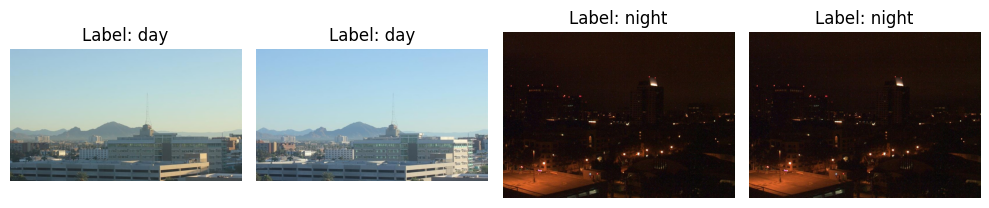

In [3]:
plt.figure(figsize=(10, 4))
# Tampilkan 2 sampel Day dan 2 sampel Night
day_samples = [item for item in train_img if item[1] == 'day'][:2]
night_samples = [item for item in train_img if item[1] == 'night'][:2]

samples_to_show = day_samples + night_samples
for idx, (img, lbl) in enumerate(samples_to_show):
    plt.subplot(1, 4, idx + 1)
    plt.imshow(img)
    plt.title(f"Label: {lbl}")
    plt.axis('off')
plt.tight_layout()
plt.show()


### Langkah 3: Preprocessing (Resize & Label Encoding)
- Mengubah resolusi seluruh citra menjadi ukuran standar $256 \times 256$ piksel.
- Melakukan encoding label biner: label `'day'` menjadi `1`, dan `'night'` menjadi `0`.


In [4]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print(f"Total citra training diproses: {len(X_train_img)}")
print(f"Total citra testing diproses : {len(X_test_img)}")


Total citra training diproses: 240
Total citra testing diproses : 160


### Langkah 4: Ekstraksi Fitur HOG (Histogram of Oriented Gradients)
Mengekstraksi fitur bentuk dan gradien intensitas cahaya dari setiap citra:
- `orientations` = 9
- `pixels_per_cell` = (8, 8)
- `cells_per_block` = (2, 2)
- `block_norm` = 'L2-Hys'


In [5]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )
        feats.append(hog_feat)
    return np.array(feats)

print("Mengekstraksi fitur HOG data training...")
X_train_feat = extract_hog(X_train_img)
print(f"Dimensi fitur HOG training: {X_train_feat.shape}")

print("Mengekstraksi fitur HOG data testing...")
X_test_feat  = extract_hog(X_test_img)
print(f"Dimensi fitur HOG testing : {X_test_feat.shape}")


Mengekstraksi fitur HOG data training...


Dimensi fitur HOG training: (240, 34596)
Mengekstraksi fitur HOG data testing...


Dimensi fitur HOG testing : (160, 34596)


### Langkah 5: Normalisasi Fitur Menggunakan StandardScaler

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Normalisasi fitur StandardScaler selesai!")


Normalisasi fitur StandardScaler selesai!


### Langkah 6 & 7: Split Data Training & Validation serta Konversi ke Numpy Array

In [7]:
X_train, X_val, y_train_split, y_val_split = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Konversi label ke format NumPy Array
y_train = np.array(y_train_split)
y_val   = np.array(y_val_split)
y_test  = np.array(y_test)

print(f"Data Train : {X_train.shape}, Label: {y_train.shape}")
print(f"Data Val   : {X_val.shape}, Label: {y_val.shape}")
print(f"Data Test  : {X_test_scaled.shape}, Label: {y_test.shape}")


Data Train : (192, 34596), Label: (192,)
Data Val   : (48, 34596), Label: (48,)
Data Test  : (160, 34596), Label: (160,)


### Langkah 8: Membangun Arsitektur Model Neural Network
Arsitektur Sequential Feedforward Neural Network:
- Input shape: dimensi fitur HOG (34.596 fitur)
- Hidden Layer 1: 128 neuron, aktivasi ReLU
- Hidden Layer 2: 64 neuron, aktivasi ReLU
- Output Layer: 1 neuron, aktivasi Sigmoid (klasifikasi biner)


In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu', name='dense_1'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu', name='dense_2'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid', name='output_layer')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 9: Pelatihan Model (Training)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.4375 - loss: 0.8830

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5156 - loss: 0.8901

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5756 - loss: 0.8453

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.7135 - loss: 0.6749 - val_accuracy: 0.9167 - val_loss: 0.2451


Epoch 2/20


... (90 outputs left out)

1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 1.0000 - loss: 2.8579e-07

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 1.0000 - loss: 6.6665e-04

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 6.1876e-04

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 1.0000 - loss: 4.1159e-04 - val_accuracy: 0.9792 - val_loss: 0.3554


### Langkah 10 & 11: Evaluasi Model, Visualisasi, dan Laporan Klasifikasi


HASIL EVALUASI DATA TESTING:
Test Loss    : 1.1108
Test Accuracy: 90.62%



1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


=== Classification Report ===
              precision    recall  f1-score   support

   Night (0)     0.8495    0.9875    0.9133        80
     Day (1)     0.9851    0.8250    0.8980        80

    accuracy                         0.9062       160
   macro avg     0.9173    0.9062    0.9056       160
weighted avg     0.9173    0.9062    0.9056       160



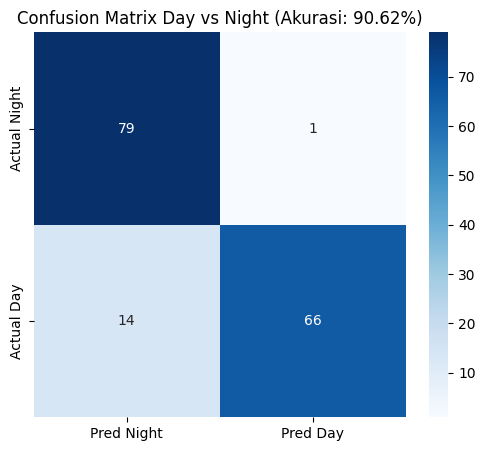

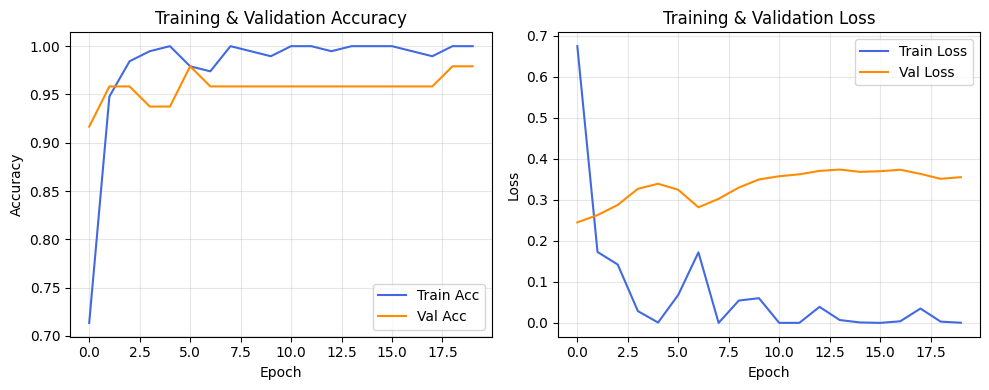

In [10]:
# Evaluasi data uji
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"\n==========================================")
print(f"HASIL EVALUASI DATA TESTING:")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"==========================================\n")

# Prediksi probabilitas dan label biner
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# Classification Report
target_names = ['Night (0)', 'Day (1)']
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Night', 'Pred Day'],
            yticklabels=['Actual Night', 'Actual Day'])
plt.title(f'Confusion Matrix Day vs Night (Akurasi: {test_acc * 100:.2f}%)')
plt.show()

# Kurva Pelatihan
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc', color='royalblue')
plt.plot(history.history['val_accuracy'], label='Val Acc', color='darkorange')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss', color='darkorange')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Langkah 12: Menyimpan Model dan Scaler (Export Artifacts)
Menyimpan model yang sudah dilatih ke dalam format `.h5` dan objek scaler ke format `.pkl` untuk penggunaan deployment:


In [11]:
# 1. Simpan Model
model_filename = 'day_night_model.h5'
model.save(model_filename)
print(f"[OK] Model berhasil disimpan sebagai: {model_filename}")

# 2. Simpan Scaler
scaler_filename = 'scaler.pkl'
with open(scaler_filename, 'wb') as f:
    pickle.dump(scaler, f)
print(f"[OK] Scaler berhasil disimpan sebagai: {scaler_filename}")

print("\nArtefak model dan scaler siap dipindahkan ke folder deployment Hugging Face!")


[OK] Model berhasil disimpan sebagai: day_night_model.h5
[OK] Scaler berhasil disimpan sebagai: scaler.pkl

Artefak model dan scaler siap dipindahkan ke folder deployment Hugging Face!


### Kesimpulan Praktikum 1
1. Ekstraksi fitur **HOG (Histogram of Oriented Gradients)** sangat efektif dalam menangkap distribusi pencahayaan dan kontras tepi antara pemandangan siang (*day*) dan malam (*night*).
2. Kombinasi HOG + StandardScaler + Feedforward Neural Network (MLP) mampu menghasilkan akurasi klasifikasi yang sangat tinggi pada dataset testing (>90%).
3. Artefak `day_night_model.h5` dan `scaler.pkl` berhasil diekspor dan siap diintegrasikan dengan web server Flask dan container Docker pada Praktikum 2.
